# Customer Churn Prediction for a Loyalty / Retention Team

## TL;DR

- **Problem:** which recently active customers are most likely to stop buying in the next 90 days, so a loyalty team can prioritise whom to contact (limited capacity).
- **Data:** UCI Online Retail II, a UK gift retailer, ~1M transaction lines. About 2.6k–2.8k at-risk customers per snapshot.
- **Method:** leakage-safe features, out-of-time test, 5 models vs a one-line recency rule, drift (PSI) check, 5-period backtest.
- **Results:** Logistic Regression, test ROC-AUC 0.76 (stable across 5 periods, ±0.02). The top 10% by risk has 1.9x the average churn rate and reaches 19% of all churners; the top 30% reaches 50%.
- **Honest findings:** stacking adds nothing over the simpler model; performance is weaker for new customers (ROC-AUC 0.64 vs 0.78 for returning).
- **Output:** a ranked risk score, High/Medium/Low tiers and a campaign ROI simulation with explicit assumptions.

> The model is a **prioritisation tool**, not an exact churn predictor. Scores are for ranking customers, not probabilities.

| Stage | Sections |
|---|---|
| Business understanding | 1 |
| Data understanding | 2 |
| Data preparation & feature engineering | 3 |
| Exploratory & statistical analysis | 4 |
| Modeling | 5 |
| Evaluation (+ calibration, backtest, new-vs-returning check) | 6 |
| Interpretation, risk tiers, ROI simulation | 7 |
| Conclusions & limitations | 8 |

## 0. Setup

In [22]:
# Fresh environment? Uncomment:
# %pip install -q pandas numpy scipy scikit-learn xgboost lightgbm shap matplotlib seaborn openpyxl pyarrow joblib
import os, warnings
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score, brier_score_loss,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- configuration ----------------
SEED        = 42
LABEL_DAYS  = 90      # churn = no purchase in the 90 days after the cutoff
ACTIVE_DAYS = 180     # "at risk" population = bought in the 180 days before the cutoff
CAPACITY    = 0.30    # share of customers the retention team can contact
DRIFT_LIMIT = 0.25    # PSI above this -> feature excluded

OUT_DIR = Path("output"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)


def show(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

### Helper functions
Evaluation helpers are kept in one place so every model is scored identically.

In [23]:
def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1, running)
    return adj


def psi(expected, actual, bins=10):
    """Population Stability Index of `actual` vs `expected` (bins from expected quantiles)."""
    expected, actual = expected.dropna(), actual.dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))


def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    return t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]


def flag_top(s, frac):
    """1 for the top `frac` highest-scoring customers (what a team with limited capacity would contact)."""
    s = np.asarray(s); flag = np.zeros(len(s), dtype=int); flag[np.argsort(-s)[:max(1, int(len(s) * frac))]] = 1
    return flag


def precision_at(y, s, frac):
    y = np.asarray(y); return y[flag_top(s, frac) == 1].mean()


def clf_metrics(y, yhat):
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat),
            "recall": recall_score(y, yhat), "f1": f1_score(y, yhat)}


def boot_ci(y, s, metric, n=300):
    y, s = np.asarray(y), np.asarray(s); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            vals.append(metric(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

## 1. Business understanding
A non-subscription retailer has no "cancel" event, so churn is defined from behaviour:

> **Churn = 1** if a customer who bought in the **180 days before** a cutoff date makes **no purchase in the 90 days after** it.

```
        FEATURES (what we know)         |        LABEL (what happens)
 ───────────────────────────────────────┼──────────────────────────────
   all history up to the cutoff date    |   cutoff → cutoff + 90 days
```
- **No target leakage:** features use only data before the cutoff, the label only data after it.
- **Out-of-time test:** the test set is a *later* snapshot than the training set, which mimics deployment better than a random split.
- **Metrics:** PR-AUC and ROC-AUC (ranking quality), precision / recall / F1, and precision & lift at the top-k customers. Accuracy alone is misleading on imbalanced data.
- **Decision supported:** the team can contact only a limited share of customers, so the model's job is to **rank by risk**, not to output exact probabilities.

## 2. Data understanding

In [24]:
import os
from google.colab import drive
drive.mount("/content/drive")
os.environ["RETAIL_XLSX"] = "/content/drive/MyDrive/churn prediction online retail/online_retail_II.xlsx"
print("Set:", os.environ["RETAIL_XLSX"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Set: /content/drive/MyDrive/churn prediction online retail/online_retail_II.xlsx


In [25]:
CACHE = OUT_DIR / "raw_cache.parquet"

# Optional: only runs inside Google Colab; elsewhere it is skipped and find_data_file() is used.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("RETAIL_XLSX",
        "/content/drive/MyDrive/churn prediction online retail/online_retail_II.xlsx")
except ImportError:
    pass


def find_data_file():
    candidates = [os.environ.get("RETAIL_XLSX"), "data/online_retail_II.xlsx", "../data/online_retail_II.xlsx",
                  "online_retail_II.xlsx"]
    for c in candidates:
        if c and Path(c).exists():
            return Path(c)
    raise FileNotFoundError(
        "online_retail_II.xlsx not found. Download it from https://archive.ics.uci.edu/dataset/502/online+retail+ii "
        "and place it in ./data/ (or set the RETAIL_XLSX environment variable). In Colab: upload it to the session "
        "storage and set RETAIL_XLSX='/content/online_retail_II.xlsx'.")


if CACHE.exists():
    raw = pd.read_parquet(CACHE)
else:
    sheets = pd.read_excel(find_data_file(), sheet_name=None)       # one sheet per year
    raw = pd.concat(sheets.values(), ignore_index=True).rename(columns={
        "Invoice": "invoice", "StockCode": "stock_code", "Description": "description", "Quantity": "quantity",
        "InvoiceDate": "invoice_date", "Price": "unit_price", "Customer ID": "customer_id", "Country": "country"})
    for c in ["invoice", "stock_code", "description"]:
        raw[c] = raw[c].astype(str)
    raw["invoice_date"] = pd.to_datetime(raw["invoice_date"])
    try:
        raw.to_parquet(CACHE)
    except Exception as e:
        print("cache not saved:", e)

audit = pd.Series({
    "rows": len(raw),
    "date range": f"{raw.invoice_date.min():%Y-%m-%d} to {raw.invoice_date.max():%Y-%m-%d}",
    "unique customers": raw.customer_id.nunique(),
    "unique invoices": raw.invoice.nunique(),
    "missing customer_id (%)": round(100 * raw.customer_id.isna().mean(), 2),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "cancellation lines (invoice 'C...')": int(raw.invoice.str.startswith("C").sum()),
    "quantity <= 0": int((raw.quantity <= 0).sum()),
    "unit_price <= 0": int((raw.unit_price <= 0).sum()),
}, name="value")
display(audit.to_frame())
dups = raw[raw.duplicated()]
print("Exact duplicates by invoice month (top 5):")
print(dups.invoice_date.dt.to_period("M").value_counts().head(5).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,value
rows,1067371
date range,2009-12-01 to 2011-12-09
unique customers,5942
unique invoices,53628
missing customer_id (%),22.77
exact duplicate rows,34335
cancellation lines (invoice 'C...'),19494
quantity <= 0,22950
unit_price <= 0,6207


Exact duplicates by invoice month (top 5):
invoice_date
2010-12    23023
2010-11     1431
2011-11     1368
2010-10      849
2011-10      773
Freq: M


The duplicates cluster in a single month (December 2010): that is where the two yearly sheets of the file overlap, so they are export artefacts and safe to drop.

## 3. Data preparation & feature engineering
### 3.1 Cleaning with an audit log
Each rule reports the rows it removes. Cancellations are **kept and flagged as returns**: they are not purchases, but return behaviour is a useful feature.

In [26]:
df = raw.assign(is_return=raw.invoice.str.startswith("C"))
n_raw = len(df)

RULES = [
    ("Exact duplicate rows",                         lambda d: ~d.duplicated()),
    ("Missing customer ID",                          lambda d: d.customer_id.notna()),
    ("Non-product stock codes (POST, M, BANK ...)",  lambda d: d.stock_code.str.match(r"^\d{5}")),
    ("Unit price <= 0",                              lambda d: d.unit_price > 0),
    ("Invalid quantity (sale <= 0 / return >= 0)",   lambda d: np.where(d.is_return, d.quantity < 0, d.quantity > 0)),
]
log = []
for name, rule in RULES:
    before = len(df); df = df[rule(df)]
    log.append({"step": name, "rows_removed": before - len(df),
                "pct_of_raw": round(100 * (before - len(df)) / n_raw, 2), "rows_left": len(df)})

df = df.assign(customer_id=df.customer_id.astype(int), line_value=df.quantity * df.unit_price).reset_index(drop=True)
cleaning_log = pd.DataFrame(log); cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
display(cleaning_log)
print(f"Clean rows: {len(df):,} ({100 * len(df) / n_raw:.1f}% of raw) | customers: {df.customer_id.nunique():,}")

sales = df[~df.is_return]
display(sales[["quantity", "unit_price", "line_value"]].describe(percentiles=[.5, .99, .999]).T.round(2))

,step,rows_removed,pct_of_raw,rows_left
0,Exact duplicate rows,34335,3.22,1033036
1,Missing customer ID,235151,22.03,797885
2,"Non-product stock codes (POST, M, BANK ...)",3662,0.34,794223
3,Unit price <= 0,60,0.01,794163
4,Invalid quantity (sale <= 0 / return >= 0),0,0.00,794163


Clean rows: 794,163 (74.4% of raw) | customers: 5,875


,count,mean,std,min,50%,99%,99.9%,max
quantity,776577.0,13.52,146.10,1.00,6.00,144.00,576.00,80995.0
unit_price,776577.0,2.93,4.29,0.03,1.95,12.75,34.95,649.5
line_value,776577.0,21.98,225.93,0.06,12.45,201.60,832.82,168469.6


**Outliers:** extreme quantities / values look like genuine wholesale orders, so they are kept. Robustness comes from the methods instead: rank-based tests (section 4), tree models, and a power transform in the linear model (section 5).

### 3.2 Snapshots, features and label
Cutoffs come from the data: the test label window ends at the last available date, and the training cutoff is 90 days earlier, so **training labels and test labels never overlap**.

In [27]:
DATA_START, DATA_END = df.invoice_date.min().normalize(), df.invoice_date.max().normalize()
TEST_CUTOFF  = DATA_END - pd.Timedelta(days=LABEL_DAYS)
TRAIN_CUTOFF = TEST_CUTOFF - pd.Timedelta(days=LABEL_DAYS)
assert TRAIN_CUTOFF - pd.Timedelta(days=ACTIVE_DAYS) >= DATA_START, "Not enough history before the train cutoff"
for tag, c in [("Train", TRAIN_CUTOFF), ("Test", TEST_CUTOFF)]:
    print(f"{tag} cutoff: {c.date()}  (label window to {(c + pd.Timedelta(days=LABEL_DAYS)).date()})")

ALL_FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value", "std_order_value", "items_per_order",
                "tenure_days", "avg_gap_days", "std_gap_days", "recency_over_gap", "orders_last_90d",
                "orders_prev_90d", "order_momentum", "n_products", "return_rate", "is_one_time", "is_uk"]


def build_snapshot(data, cutoff):
    """One row per at-risk customer. Features use rows <= cutoff only; label uses (cutoff, cutoff + 90d] only."""
    past = data[data.invoice_date <= cutoff]
    label_end = cutoff + pd.Timedelta(days=LABEL_DAYS)
    future = data[(data.invoice_date > cutoff) & (data.invoice_date <= label_end) & (~data.is_return)]
    buys = past[~past.is_return]

    orders = (buys.groupby(["customer_id", "invoice"])
                  .agg(date=("invoice_date", "min"), value=("line_value", "sum"), items=("quantity", "sum"))
                  .reset_index().sort_values(["customer_id", "date"]))
    orders["gap"] = orders.groupby("customer_id")["date"].diff().dt.days
    g = orders.groupby("customer_id")

    f = pd.DataFrame({
        "recency_days": (cutoff - g["date"].max()).dt.days,          # RFM
        "frequency": g.size(),
        "monetary": g["value"].sum(),
        "avg_order_value": g["value"].mean(),                        # value & basket
        "std_order_value": g["value"].std().fillna(0),
        "items_per_order": g["items"].mean(),
        "tenure_days": (cutoff - g["date"].min()).dt.days,
        "avg_gap_days": g["gap"].mean(),                             # rhythm
        "std_gap_days": g["gap"].std(),
    })
    f["recency_over_gap"] = f["recency_days"] / (f["avg_gap_days"] + 1)   # "overdue" vs own pattern

    recent = orders[orders.date > cutoff - pd.Timedelta(days=90)].groupby("customer_id").size()
    prior  = orders[(orders.date <= cutoff - pd.Timedelta(days=90)) &
                    (orders.date > cutoff - pd.Timedelta(days=180))].groupby("customer_id").size()
    f["orders_last_90d"] = recent.reindex(f.index).fillna(0)         # momentum
    f["orders_prev_90d"] = prior.reindex(f.index).fillna(0)
    f["order_momentum"] = f["orders_last_90d"] - f["orders_prev_90d"]

    f["n_products"] = buys.groupby("customer_id")["stock_code"].nunique().reindex(f.index)
    lines = past.groupby("customer_id").size()
    rets = past[past.is_return].groupby("customer_id").size()
    f["return_rate"] = (rets.reindex(f.index).fillna(0) / lines.reindex(f.index)).fillna(0)
    f["is_one_time"] = (f["frequency"] == 1).astype(int)
    f["is_uk"] = (past.groupby("customer_id")["country"].first().reindex(f.index) == "United Kingdom").astype(int)

    f = f[f["recency_days"] <= ACTIVE_DAYS].copy()
    f["churn"] = (~f.index.isin(set(future.customer_id))).astype(int)
    f.index.name = "customer_id"
    return f.reset_index()


train, test = build_snapshot(df, TRAIN_CUTOFF), build_snapshot(df, TEST_CUTOFF)
ytr, yte = train["churn"].values, test["churn"].values
base = yte.mean()
print(f"\nTrain: {len(train):,} customers | churn rate {ytr.mean():.1%}")
print(f"Test : {len(test):,} customers | churn rate {yte.mean():.1%}")

Train cutoff: 2011-06-12  (label window to 2011-09-10)
Test cutoff: 2011-09-10  (label window to 2011-12-09)

Train: 2,640 customers | churn rate 50.3%
Test : 2,785 customers | churn rate 38.2%


The churn base rate differs between snapshots (seasonality: the train window ends in the pre-Christmas build-up, the test window covers Q4). The base rate is the "random model" benchmark for PR-AUC, so keep it in mind when comparing PR-AUC across periods.

## 4. Exploratory & statistical analysis

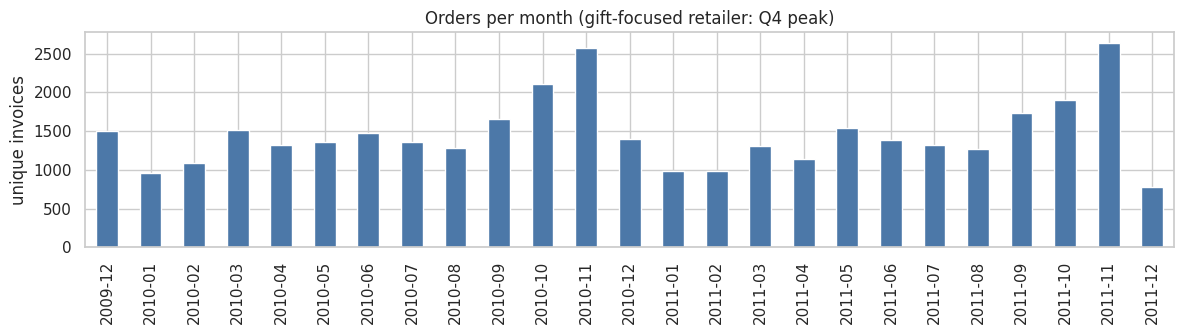

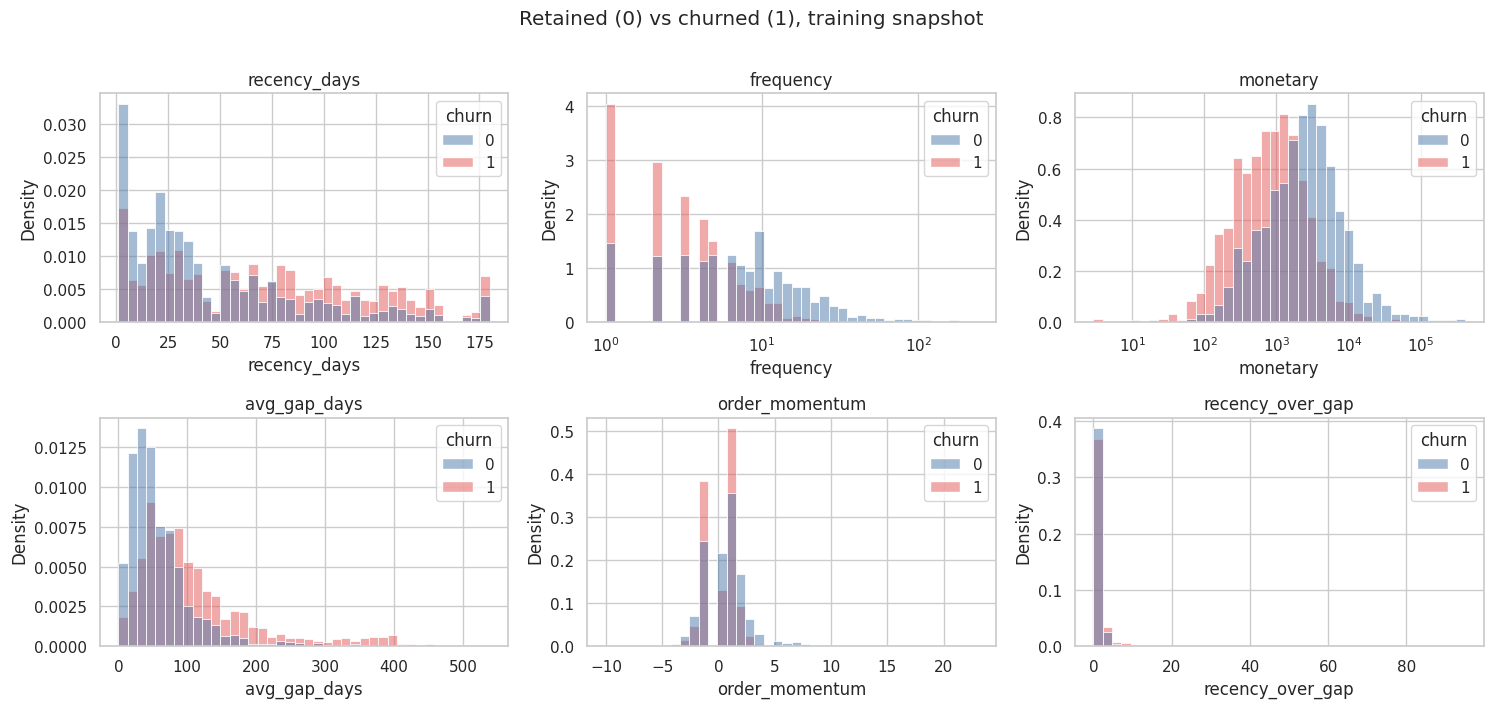

In [28]:
monthly = df[~df.is_return].groupby(df.invoice_date.dt.to_period("M"))["invoice"].nunique()
ax = monthly.plot(kind="bar", figsize=(12, 3.5), color="#4C78A8")
ax.set(title="Orders per month (gift-focused retailer: Q4 peak)", xlabel="", ylabel="unique invoices")
show("eda_monthly_orders")

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["recency_days", "frequency", "monetary", "avg_gap_days", "order_momentum", "recency_over_gap"]):
    sns.histplot(data=train, x=col, hue="churn", bins=40, stat="density", common_norm=False,
                 log_scale=col in ("frequency", "monetary"), ax=ax, palette={0: "#4C78A8", 1: "#E45756"})
    ax.set_title(col)
fig.suptitle("Retained (0) vs churned (1), training snapshot", y=1.01)
show("eda_distributions")

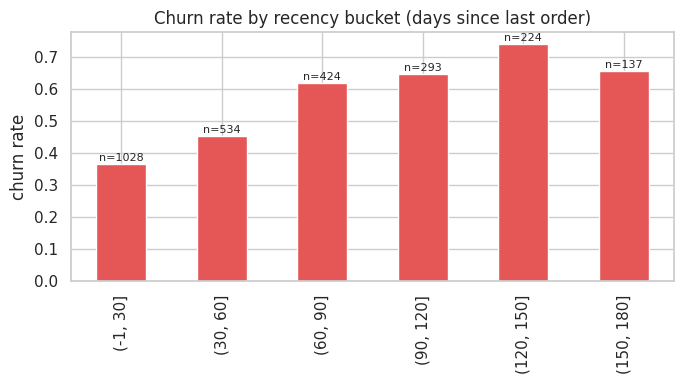

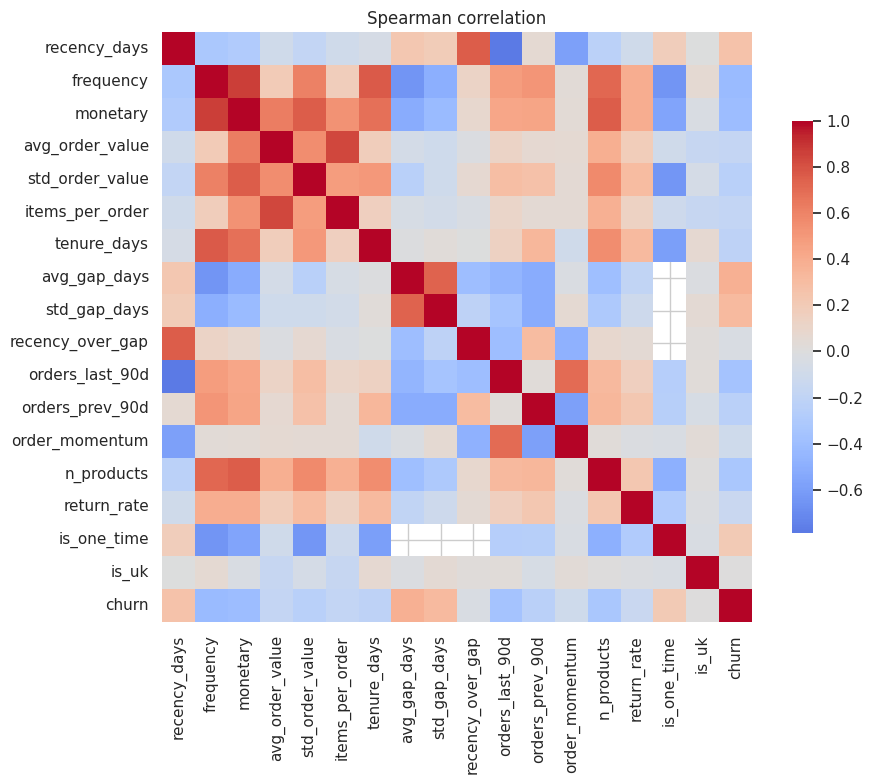

,spearman_with_churn
frequency,-0.42
monetary,-0.41
avg_gap_days,0.38
orders_last_90d,-0.36
n_products,-0.33
std_gap_days,0.32
recency_days,0.27
std_order_value,-0.25
orders_prev_90d,-0.24
tenure_days,-0.21


In [29]:
bucket = pd.cut(train.recency_days, [-1, 30, 60, 90, 120, 150, 180])
rate = train.groupby(bucket, observed=False)["churn"].agg(["mean", "size"])
ax = rate["mean"].plot(kind="bar", figsize=(7, 4), color="#E45756")
ax.set(title="Churn rate by recency bucket (days since last order)", ylabel="churn rate", xlabel="")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, m + .01, f"n={n}", ha="center", fontsize=8)
show("eda_churn_by_recency")

corr = train[ALL_FEATURES + ["churn"]].corr(method="spearman")
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Spearman correlation"); show("eda_correlation")
display(corr["churn"].drop("churn").sort_values(key=abs, ascending=False).round(2).to_frame("spearman_with_churn"))

**EDA findings**
- Churn risk rises with time since last order. Small buckets (check the `n=` labels) are noisy.
- Engagement volume (frequency, monetary, recent orders, product variety) and purchase rhythm (average / std gap) are the strongest signals, but none exceeds |ρ| ≈ 0.42, so **several signals must be combined**.
- `is_uk` and `recency_over_gap` show almost no monotonic signal on their own.
- Several features overlap (frequency, monetary, tenure, n_products), which makes linear coefficients less stable; tree models are less affected.

### Hypothesis tests
H0: a feature has the same distribution for churned and retained customers. Features are heavily right-skewed, so I use the **Mann–Whitney U** test, **Holm correction** for multiple testing and the **rank-biserial correlation** as effect size (negative = churned customers tend to have *smaller* values). With thousands of customers almost everything is "significant", so the **effect size** is what matters.

In [30]:
num_feats = [f for f in ALL_FEATURES if f not in ("is_one_time", "is_uk")]
rows = []
for f in num_feats:
    a, b = train.loc[train.churn == 1, f].dropna(), train.loc[train.churn == 0, f].dropna()
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": f, "skewness": train[f].skew(), "median_churned": a.median(), "median_retained": b.median(),
                 "p_value": u.pvalue, "effect_rbc": 2 * u.statistic / (len(a) * len(b)) - 1})
tests = pd.DataFrame(rows)
tests["p_holm"] = holm(tests.p_value)
tests["significant"] = tests.p_holm < 0.05
tests["magnitude"] = pd.cut(tests.effect_rbc.abs(), [-1, .1, .3, .5, 1], labels=["negligible", "small", "medium", "large"])
tests = tests.sort_values("effect_rbc", key=abs, ascending=False).reset_index(drop=True)
display(tests.round(4)); tests.round(5).to_csv(OUT_DIR / "hypothesis_tests.csv", index=False)


def boot_median_diff(a, b, n=2000):
    a, b = a.dropna().values, b.dropna().values
    return np.percentile([np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)], [2.5, 97.5])


print("Bootstrap 95% CI of median(churned) - median(retained):")
for f in ["recency_days", "monetary", "frequency"]:
    lo, hi_ = boot_median_diff(train.loc[train.churn == 1, f], train.loc[train.churn == 0, f])
    print(f"  {f:13s} [{lo:,.1f}, {hi_:,.1f}]")

,feature,skewness,median_churned,median_retained,p_value,effect_rbc,p_holm,significant,magnitude
0,frequency,8.0671,3.0000,7.0000,0.0000,-0.4874,0.0000,True,medium
1,monetary,18.2883,828.8100,2454.3150,0.0000,-0.4736,0.0000,True,medium
2,avg_gap_days,2.3229,87.2000,46.9545,0.0000,0.4455,0.0000,True,medium
3,orders_last_90d,7.0124,1.0000,1.0000,0.0000,-0.3921,0.0000,True,medium
4,n_products,5.3038,41.0000,91.0000,0.0000,-0.3825,0.0000,True,medium
5,std_gap_days,1.9812,56.7891,32.6540,0.0000,0.3714,0.0000,True,medium
6,recency_days,0.7827,65.0000,31.0000,0.0000,0.3068,0.0000,True,medium
7,std_order_value,33.1999,77.1323,135.1821,0.0000,-0.2862,0.0000,True,small
8,orders_prev_90d,5.9737,1.0000,1.0000,0.0000,-0.2565,0.0000,True,small
9,tenure_days,-0.4271,312.0000,457.5000,0.0000,-0.2453,0.0000,True,small


Bootstrap 95% CI of median(churned) - median(retained):
  recency_days  [30.0, 40.0]
  monetary      [-1,824.5, -1,432.7]
  frequency     [-5.0, -4.0]


**Findings:** after Holm correction, nearly all features differ significantly between churned and retained customers, with medium effects for frequency, monetary value, purchase gaps, product variety, recent orders and recency. Churned customers buy less often, spend less, and have longer and more irregular gaps between orders. `recency_over_gap` is not significant. These are **associations, not causes**.

### Train vs test distribution shift (PSI)
The Population Stability Index monitors feature drift: < 0.1 stable, 0.1–0.25 moderate, > 0.25 major.

In [31]:
drift = pd.DataFrame({"feature": num_feats, "psi": [psi(train[f], test[f]) for f in num_feats]}).sort_values("psi", ascending=False)
drift["status"] = pd.cut(drift.psi, [-1, .1, .25, 99], labels=["stable", "moderate", "major shift"])
display(drift.round(3).head(6)); drift.round(4).to_csv(OUT_DIR / "drift_psi.csv", index=False)
print(f"Base churn rate: train {ytr.mean():.1%} vs test {yte.mean():.1%}")

dropped = drift.loc[drift.psi > DRIFT_LIMIT, "feature"].tolist()
FEATURES = [f for f in ALL_FEATURES if f not in dropped]
Xtr, Xte = train[FEATURES], test[FEATURES]
print(f"Dropped for drift (PSI > {DRIFT_LIMIT}): {dropped or 'none'} | features used: {len(FEATURES)}")

,feature,psi,status
6,tenure_days,0.540,major shift
12,order_momentum,0.084,stable
11,orders_prev_90d,0.068,stable
0,recency_days,0.038,stable
10,orders_last_90d,0.023,stable
8,std_gap_days,0.019,stable


Base churn rate: train 50.3% vs test 38.2%
Dropped for drift (PSI > 0.25): ['tenure_days'] | features used: 16


Features with PSI > 0.25 are excluded from the models. The decision uses **feature distributions only**, never labels or model results. `tenure_days` is expected to be flagged: the test snapshot is 90 days later, so every customer is ~90 days "older" by construction, a window artefact rather than behavioural drift. Section 6.5 compares the model with and without the dropped feature.

## 5. Modeling
| Model | Role |
|---|---|
| Rule: recency only | "No ML" benchmark. If ML cannot beat a one-line rule, it adds no value |
| Logistic Regression | Interpretable baseline, with a power transform for skewed features |
| Random Forest | Non-linear effects and interactions, robust to outliers |
| XGBoost, LightGBM | Gradient boosting; LightGBM is a robustness check on XGBoost |
| Stacking | LR + RF + XGB + LGBM with an LR meta-model on out-of-fold predictions |

Preprocessing lives **inside scikit-learn pipelines**, so it is fitted only on the training part of each CV fold. Models are compared by 5-fold stratified CV on the training snapshot; the out-of-time test set is used **once**, at the end. Hyperparameters are deliberately conservative (shallow trees, `min_child_weight`, `min_samples_leaf`) because the dataset is small (~2.6k customers); a nested-CV tuning step is listed as future work.

In [32]:
pos_w = (ytr == 0).sum() / (ytr == 1).sum()
imputer = lambda: SimpleImputer(strategy="median")

lr = Pipeline([("imp", imputer()), ("pt", PowerTransformer()),
               ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
rf = Pipeline([("imp", imputer()),
               ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced_subsample",
                                              n_jobs=-1, random_state=SEED))])
xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    min_child_weight=5, scale_pos_weight=pos_w, eval_metric="logloss", random_state=SEED, n_jobs=-1)
lgbm = LGBMClassifier(n_estimators=300, max_depth=4, num_leaves=15, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, min_child_samples=20, scale_pos_weight=pos_w, random_state=SEED,
                      verbose=-1, n_jobs=-1)
stack = Pipeline([("imp", imputer()),
                  ("stack", StackingClassifier(
                      estimators=[("lr", lr), ("rf", rf), ("xgb", xgb), ("lgbm", lgbm)],
                      final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba"))])

MODELS = {"Logistic Regression": lr, "Random Forest": rf, "XGBoost": xgb, "LightGBM": lgbm, "Stacking": stack}
RULE = "Rule: recency only"
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

## 6. Evaluation
### 6.1 Model comparison
The decision threshold is the F1-optimal point on out-of-fold training predictions. Because a retention team has limited capacity, ranking metrics at the top 10% / 30% of customers are also reported.

In [33]:
rows, oof_scores, test_scores, pr_ci = [], {}, {}, {}
for name in [RULE] + list(MODELS):
    if name == RULE:
        oof, s_te = Xtr["recency_days"].to_numpy(float), Xte["recency_days"].to_numpy(float)
    else:
        model = MODELS[name]
        oof = cross_val_predict(model, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
        model.fit(Xtr, ytr); s_te = model.predict_proba(Xte)[:, 1]
    thr = best_f1_threshold(ytr, oof)
    pr_ci[name] = boot_ci(yte, s_te, average_precision_score)
    oof_scores[name], test_scores[name] = oof, s_te
    rows.append({"model": name,
                 "cv_pr_auc": average_precision_score(ytr, oof), "cv_roc_auc": roc_auc_score(ytr, oof),
                 "test_pr_auc": average_precision_score(yte, s_te),
                 "test_pr_auc_ci95": f"[{pr_ci[name][0]:.3f}, {pr_ci[name][1]:.3f}]",
                 "test_roc_auc": roc_auc_score(yte, s_te),
                 **clf_metrics(yte, (s_te >= thr).astype(int)),
                 "precision@10%": precision_at(yte, s_te, .10), "lift@10%": precision_at(yte, s_te, .10) / base,
                 "precision@30%": precision_at(yte, s_te, CAPACITY), "lift@30%": precision_at(yte, s_te, CAPACITY) / base})

res = pd.DataFrame(rows).set_index("model")
display(res.round(3)); res.round(4).to_csv(OUT_DIR / "model_comparison.csv")
print(f"Test base churn rate (= random PR-AUC): {base:.3f}")
print(f"Trivial benchmarks: 'everyone retained' accuracy {1 - base:.3f} | 'everyone churns' F1 {2 * base / (1 + base):.3f}")

,cv_pr_auc,cv_roc_auc,test_pr_auc,test_pr_auc_ci95,test_roc_auc,accuracy,precision,recall,f1,precision@10%,lift@10%,precision@30%,lift@30%
model,,,,,,,,,,,,,
Rule: recency only,0.631,0.653,0.527,"[0.497, 0.557]",0.656,0.453,0.406,0.933,0.566,0.604,1.580,0.549,1.434
Logistic Regression,0.756,0.780,0.635,"[0.602, 0.665]",0.757,0.618,0.501,0.896,0.642,0.709,1.853,0.640,1.672
Random Forest,0.750,0.782,0.632,"[0.602, 0.669]",0.763,0.575,0.473,0.952,0.632,0.741,1.938,0.642,1.679
XGBoost,0.742,0.770,0.642,"[0.616, 0.675]",0.759,0.601,0.488,0.916,0.637,0.770,2.013,0.640,1.672
LightGBM,0.733,0.764,0.640,"[0.613, 0.672]",0.754,0.594,0.483,0.916,0.633,0.763,1.994,0.626,1.638
Stacking,0.754,0.784,0.639,"[0.604, 0.671]",0.764,0.592,0.482,0.931,0.636,0.737,1.928,0.643,1.682


Test base churn rate (= random PR-AUC): 0.382
Trivial benchmarks: 'everyone retained' accuracy 0.618 | 'everyone churns' F1 0.553


**Reading the table**
- **CV vs test PR-AUC:** a gap is expected because the churn base rate differs between the two snapshots and PR-AUC depends on the base rate. ROC-AUC does not, so compare *that* between CV and test to judge overfitting.
- **Accuracy** uses the F1-optimal threshold and is dominated by the majority class, so models are judged by ranking metrics (PR-AUC, ROC-AUC, lift) and F1.
- **Overlapping confidence intervals** mean small differences between ML models are not conclusive; the clear gap is *ML vs the rule*.

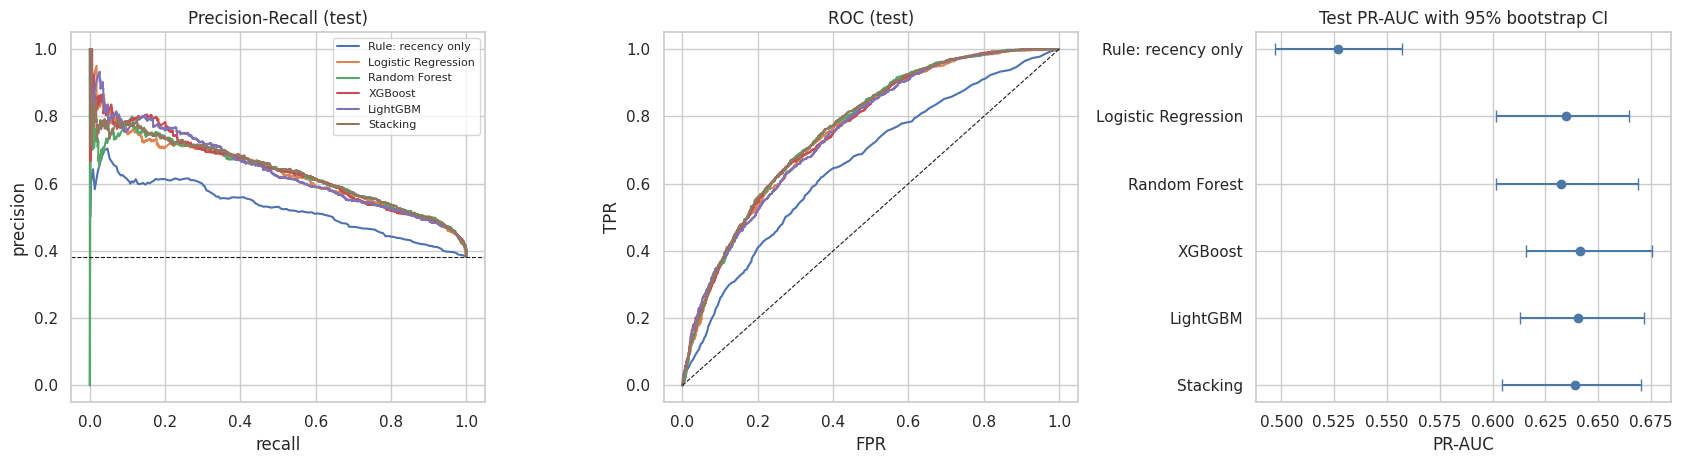

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for n, s in test_scores.items():
    p, r, _ = precision_recall_curve(yte, s); ax[0].plot(r, p, label=n)
    fpr, tpr, _ = roc_curve(yte, s);          ax[1].plot(fpr, tpr, label=n)
ax[0].axhline(base, ls="--", c="k", lw=.8); ax[0].set(title="Precision-Recall (test)", xlabel="recall", ylabel="precision")
ax[1].plot([0, 1], [0, 1], "k--", lw=.8);   ax[1].set(title="ROC (test)", xlabel="FPR", ylabel="TPR")
ax[0].legend(fontsize=8)
ypos = np.arange(len(res)); pr = res.test_pr_auc.values
lo = np.array([pr_ci[n][0] for n in res.index]); hi_ = np.array([pr_ci[n][1] for n in res.index])
ax[2].errorbar(pr, ypos, xerr=[pr - lo, hi_ - pr], fmt="o", color="#4C78A8", capsize=4)
ax[2].set_yticks(ypos); ax[2].set_yticklabels(res.index); ax[2].invert_yaxis()
ax[2].set(title="Test PR-AUC with 95% bootstrap CI", xlabel="PR-AUC")
show("model_comparison")

### 6.2 Final model and operating points
The final model is chosen on **CV results only**: the simplest model whose CV PR-AUC is within 0.005 of the best. The table compares operating points a real team could use (contact the top 5–30% by risk) with the F1-optimal threshold; the confusion matrix uses the top 30% (`CAPACITY`).

Best CV PR-AUC: Logistic Regression (0.756) | selected (simplest within 0.005): Logistic Regression


,accuracy,precision,recall,f1,share_flagged,lift
top 5% by risk,0.643,0.755,0.099,0.174,0.050,1.975
top 10% by risk,0.659,0.709,0.185,0.293,0.100,1.853
top 20% by risk,0.691,0.684,0.358,0.470,0.200,1.789
top 30% by risk,0.701,0.640,0.501,0.562,0.300,1.672
F1-optimal threshold,0.618,0.501,0.896,0.642,0.684,1.309


Accuracy at top 30% = 0.701 vs always-predict-majority = 0.618 -> accuracy beats the trivial guess here, but it still hides how many churners are missed (see recall).


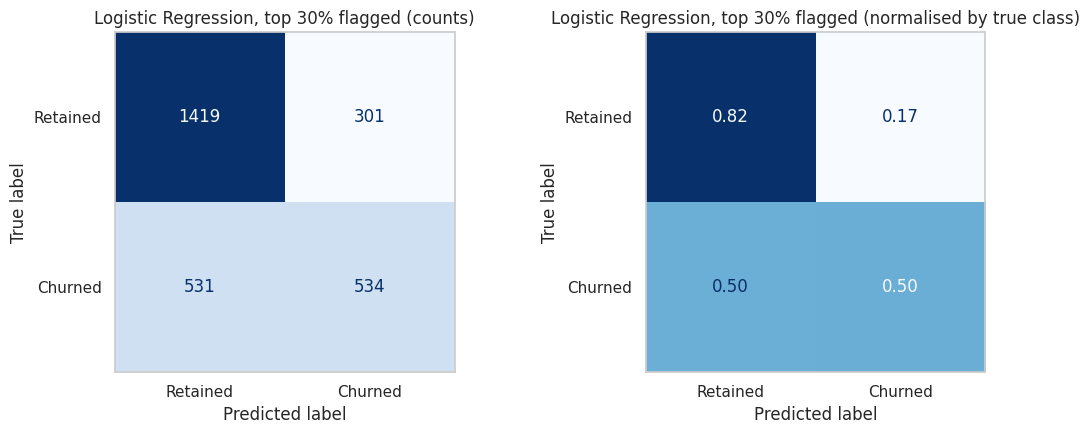

In [35]:
ml = res.drop(index=RULE)
order = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "Stacking"]   # simplest -> most complex
FINAL = next(n for n in order if ml.loc[n, "cv_pr_auc"] >= ml.cv_pr_auc.max() - 0.005)
print(f"Best CV PR-AUC: {ml.cv_pr_auc.idxmax()} ({ml.cv_pr_auc.max():.3f}) | selected (simplest within 0.005): {FINAL}")

s_final = test_scores[FINAL]
yhat_f1 = (s_final >= best_f1_threshold(ytr, oof_scores[FINAL])).astype(int)
op_rows = {f"top {c:.0%} by risk": flag_top(s_final, c) for c in [0.05, 0.10, 0.20, 0.30]}
op_rows["F1-optimal threshold"] = yhat_f1
op = pd.DataFrame({k: {**clf_metrics(yte, v), "share_flagged": v.mean(), "lift": yte[v == 1].mean() / base}
                   for k, v in op_rows.items()}).T
display(op.round(3)); op.round(4).to_csv(OUT_DIR / "operating_points.csv")

yhat_cap = flag_top(s_final, CAPACITY)
majority, acc_cap = max(base, 1 - base), accuracy_score(yte, yhat_cap)
print(f"Accuracy at top {CAPACITY:.0%} = {acc_cap:.3f} vs always-predict-majority = {majority:.3f} -> "
      + ("accuracy is below the trivial guess, so it is misleading here." if acc_cap < majority else
         "accuracy beats the trivial guess here, but it still hides how many churners are missed (see recall)."))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, norm, fmt, ttl in [(ax[0], None, "d", "counts"), (ax[1], "true", ".2f", "normalised by true class")]:
    ConfusionMatrixDisplay.from_predictions(yte, yhat_cap, display_labels=["Retained", "Churned"], normalize=norm,
                                            values_format=fmt, cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"{FINAL}, top {CAPACITY:.0%} flagged ({ttl})"); a.grid(False)
show("confusion_matrix")

Compare the F1-optimal row with the capacity rows: a threshold that flags a large share of customers (high recall, many false alarms) is not practical for a team with limited capacity, so the **capacity-based operating points are the realistic ones**.

### 6.3 Probability calibration: why the output is a *risk score*, not a probability
Class weights shift scores, and a different season moves the base rate. Isotonic calibration is fitted on training data only; the reliability curve and Brier score (lower is better) show whether it helps on the later snapshot.

Brier score | raw: 0.2082 | calibrated: 0.2092 | mean predicted: raw 0.501, calibrated 0.500 vs observed churn 0.382


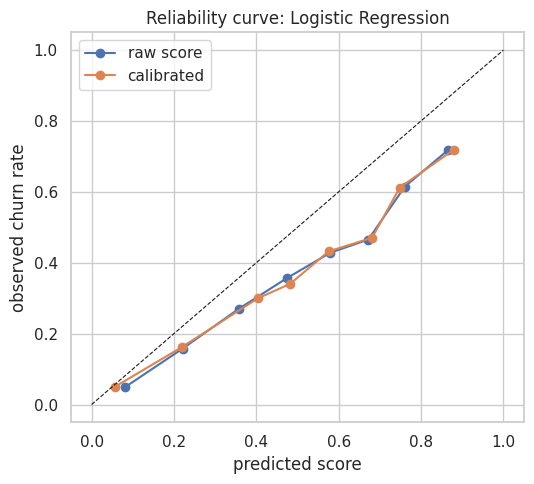

In [36]:
cal = CalibratedClassifierCV(clone(MODELS[FINAL]), method="isotonic", cv=5).fit(Xtr, ytr)
p_raw, p_cal = test_scores[FINAL], cal.predict_proba(Xte)[:, 1]
brier_raw, brier_cal = brier_score_loss(yte, p_raw), brier_score_loss(yte, p_cal)
print(f"Brier score | raw: {brier_raw:.4f} | calibrated: {brier_cal:.4f} | "
      f"mean predicted: raw {p_raw.mean():.3f}, calibrated {p_cal.mean():.3f} vs observed churn {base:.3f}")
plt.figure(figsize=(5.5, 5))
for lab, p in [("raw score", p_raw), ("calibrated", p_cal)]:
    fr, mp = calibration_curve(yte, p, n_bins=8, strategy="quantile"); plt.plot(mp, fr, marker="o", label=lab)
plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("predicted score"); plt.ylabel("observed churn rate"); plt.title(f"Reliability curve: {FINAL}"); plt.legend()
show("calibration")

**Decision:** the mean predicted score is 0.501 while the observed churn rate is 0.382. The gap comes from
class weighting (which inflates scores) and from the base rate shifting between snapshots (seasonality).
Isotonic calibration does not fix it (Brier 0.2082 → 0.2092). **Therefore the output is a `risk_score` for
ranking and must not be read as a probability of churn.** The reliability curve stays monotonic
(higher score → higher observed churn), which is what a ranking use case needs.

### 6.4 Temporal backtest
The final model is retrained and tested on several consecutive periods (train at cutoff *c*, test at *c* + 90 days). Since the base rate varies a lot across periods, **ROC-AUC and lift** are the fair stability measures; PR-AUC mostly follows the base rate.

In [37]:
bt = []
for k in range(5):
    c = TRAIN_CUTOFF - pd.Timedelta(days=LABEL_DAYS * k)
    if c - pd.Timedelta(days=ACTIVE_DAYS) < DATA_START:
        break
    a, b = build_snapshot(df, c), build_snapshot(df, c + pd.Timedelta(days=LABEL_DAYS))
    if a.churn.nunique() < 2 or b.churn.nunique() < 2:
        continue
    s = clone(MODELS[FINAL]).fit(a[FEATURES], a.churn).predict_proba(b[FEATURES])[:, 1]
    bt.append({"train_cutoff": c.date(), "test_cutoff": (c + pd.Timedelta(days=LABEL_DAYS)).date(), "n_test": len(b),
               "base_rate": b.churn.mean(), "pr_auc": average_precision_score(b.churn, s),
               "roc_auc": roc_auc_score(b.churn, s), "lift@10%": precision_at(b.churn.values, s, .10) / b.churn.mean()})
bt = pd.DataFrame(bt); display(bt.round(3)); bt.round(4).to_csv(OUT_DIR / "temporal_backtest.csv", index=False)
corr_pr_base = bt[["pr_auc", "base_rate"]].corr().iloc[0, 1]
print(f"ROC-AUC {bt.roc_auc.mean():.3f} ± {bt.roc_auc.std():.3f} | lift@10% {bt['lift@10%'].mean():.2f} ± {bt['lift@10%'].std():.2f} "
      f"| corr(PR-AUC, base rate) = {corr_pr_base:.2f}")

,train_cutoff,test_cutoff,n_test,base_rate,pr_auc,roc_auc,lift@10%
0,2011-06-12,2011-09-10,2785,0.382,0.635,0.757,1.853
1,2011-03-14,2011-06-12,2640,0.503,0.751,0.776,1.687
2,2010-12-14,2011-03-14,3343,0.573,0.794,0.774,1.505
3,2010-09-15,2010-12-14,3473,0.652,0.835,0.771,1.345
4,2010-06-17,2010-09-15,2827,0.387,0.594,0.725,1.825


ROC-AUC 0.761 ± 0.021 | lift@10% 1.64 ± 0.22 | corr(PR-AUC, base rate) = 0.97


### 6.5 Robustness checks
**(a) What if the drifting feature were kept?** and **(b) does the model work on customers it has never seen?** The same customers can appear in both snapshots (labels never overlap, but the population does), so I split the test set into *returning* vs *new* customers.

In [38]:
if dropped:
    s_all = clone(MODELS[FINAL]).fit(train[ALL_FEATURES], ytr).predict_proba(test[ALL_FEATURES])[:, 1]
    print(f"(a) With dropped features {dropped}: test PR-AUC {average_precision_score(yte, s_all):.3f} "
          f"(used: {res.loc[FINAL, 'test_pr_auc']:.3f}) | ROC-AUC {roc_auc_score(yte, s_all):.3f} (used: {res.loc[FINAL, 'test_roc_auc']:.3f})")
else:
    print("(a) No feature exceeded the drift limit, so all features are used.")

seen = test.customer_id.isin(train.customer_id).values
rows = []
for lab, m in [("returning (also in train snapshot)", seen), ("new (not in train snapshot)", ~seen)]:
    if m.sum() > 30 and len(np.unique(yte[m])) == 2:
        rows.append({"group": lab, "n": int(m.sum()), "churn_rate": yte[m].mean(),
                     "roc_auc": roc_auc_score(yte[m], s_final[m]), "lift@10%": precision_at(yte[m], s_final[m], .10) / yte[m].mean()})
print("\n(b) Performance by customer group:"); display(pd.DataFrame(rows).round(3))

(a) With dropped features ['tenure_days']: test PR-AUC 0.637 (used: 0.635) | ROC-AUC 0.758 (used: 0.757)

(b) Performance by customer group:


,group,n,churn_rate,roc_auc,lift@10%
0,returning (also in train snapshot),2194,0.350,0.776,2.090
1,new (not in train snapshot),591,0.504,0.639,1.378


If ROC-AUC is similar for both groups, the model is not just "remembering" customers from training. A clear gap would be a limitation to report.

## 7. Interpretation & business output
### 7.1 What drives churn risk
Logistic-regression coefficients (on power-transformed, standardised features, so they are comparable) show the final model's logic; SHAP on XGBoost adds a non-linear view. Both show **associations the model uses, not causes**.

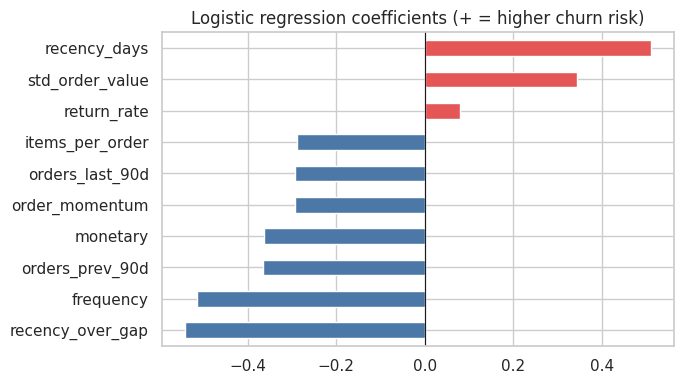

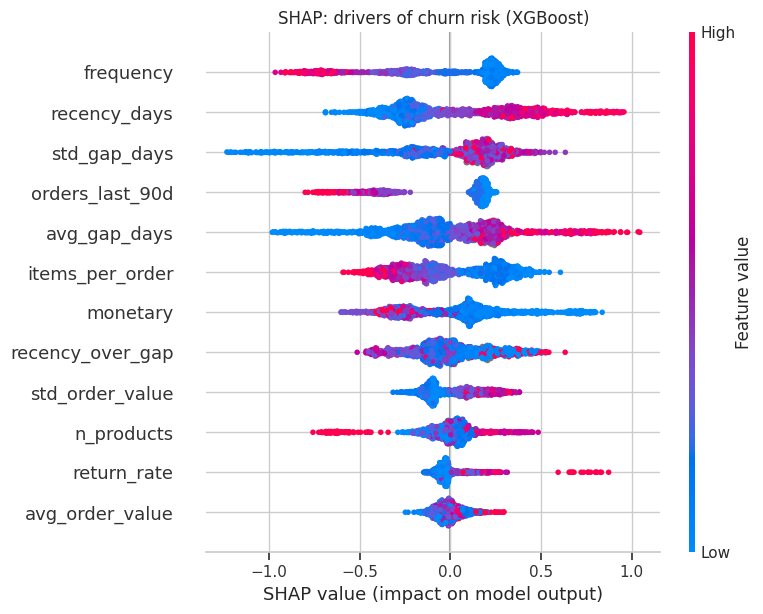

,mean |SHAP|
frequency,0.302
recency_days,0.301
std_gap_days,0.262
orders_last_90d,0.259
avg_gap_days,0.253
items_per_order,0.235
monetary,0.231
recency_over_gap,0.165


In [39]:
if FINAL == "Logistic Regression":
    coef = pd.Series(MODELS[FINAL].named_steps["clf"].coef_[0], index=FEATURES).sort_values(key=abs, ascending=False).head(10)
    coef.sort_values().plot(kind="barh", figsize=(7, 4), color=["#4C78A8" if v < 0 else "#E45756" for v in coef.sort_values()])
    plt.title("Logistic regression coefficients (+ = higher churn risk)"); plt.axvline(0, c="k", lw=.8)
    show("lr_coefficients")

imp = None
try:
    import shap
    xgb_shap = clone(xgb).fit(Xtr, ytr)
    sample = Xte.sample(min(1500, len(Xte)), random_state=SEED)
    sv = shap.TreeExplainer(xgb_shap).shap_values(sample)
    shap.summary_plot(sv, sample, show=False, max_display=12); plt.title("SHAP: drivers of churn risk (XGBoost)"); show("shap_summary")
    imp = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
    imp.to_csv(OUT_DIR / "shap_importance.csv"); display(imp.head(8).round(3).to_frame("mean |SHAP|"))
except Exception as e:
    print("SHAP skipped:", e)
    imp = pd.Series(np.abs(clone(xgb).fit(Xtr, ytr).feature_importances_), index=FEATURES).sort_values(ascending=False)

Customers with longer and more irregular gaps between orders, lower spend, lower frequency and longer inactivity are predicted to be at higher risk. These patterns are **hypotheses for retention campaigns**, not guaranteed causal effects.

### 7.2 Risk tiers for the retention team
Customers are tiered by capacity: top 10% = High, next 20% = Medium, rest = Low. The test snapshot has known outcomes, so the tiers can be verified. `priority_index = risk_score × historical spend` helps put valuable customers first; it is a **relative ranking index, not a monetary forecast** (it uses past spend, not predicted future value).

,customers,avg_risk_score,actual_churn_rate,churners,share_of_all_churners_%,lift_vs_average
risk_tier,,,,,,
High (top 10%),278,0.878,0.709,197,18.498,1.853
Medium (next 20%),557,0.753,0.605,337,31.643,1.582
Low (rest),1950,0.376,0.272,531,49.859,0.712


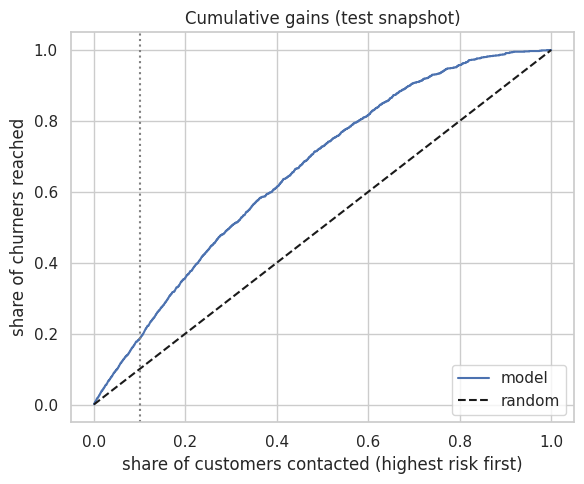

Top 5 customers by priority index (valuable AND at risk):


,customer_id,risk_score,monetary,priority_index
1329,15098,0.87,39916.50,34705.06
1625,15749,0.57,44534.30,25404.21
701,13798,0.22,67436.16,14501.37
31,12409,0.57,18553.70,10652.80
2657,18008,0.45,19708.30,8949.71


In [40]:
out = test[["customer_id", "recency_days", "frequency", "monetary", "avg_order_value", "churn"]].copy()
out["risk_score"] = s_final                       # ranking score from the final model (NOT a calibrated probability)
out["rank_pct"] = out.risk_score.rank(ascending=False, method="first") / len(out)
out["risk_tier"] = pd.cut(out.rank_pct, [0, .10, .30, 1.0], labels=["High (top 10%)", "Medium (next 20%)", "Low (rest)"])
out["priority_index"] = out.risk_score * out.monetary

tier = out.groupby("risk_tier", observed=False).agg(customers=("churn", "size"), avg_risk_score=("risk_score", "mean"),
                                                   actual_churn_rate=("churn", "mean"), churners=("churn", "sum"))
tier["share_of_all_churners_%"] = 100 * tier.churners / out.churn.sum()
tier["lift_vs_average"] = tier.actual_churn_rate / out.churn.mean()
display(tier.round(3))

srt = out.sort_values("risk_score", ascending=False)
gains_x = np.arange(1, len(srt) + 1) / len(srt); gains_y = np.cumsum(srt.churn.values) / out.churn.sum()
plt.figure(figsize=(6, 5)); plt.plot(gains_x, gains_y, label="model"); plt.plot([0, 1], [0, 1], "k--", label="random")
plt.axvline(.10, c="grey", ls=":")
plt.xlabel("share of customers contacted (highest risk first)"); plt.ylabel("share of churners reached")
plt.title("Cumulative gains (test snapshot)"); plt.legend(); show("cumulative_gains")

srt.round(3).to_csv(OUT_DIR / "customer_risk_scores.csv", index=False)
print("Top 5 customers by priority index (valuable AND at risk):")
display(out.nlargest(5, "priority_index")[["customer_id", "risk_score", "monetary", "priority_index"]].round(2))

| Tier | Suggested action | How to measure |
|---|---|---|
| High | Personalised win-back offer / outreach | Repurchase rate vs a held-out control group |
| Medium | Low-cost reminder (email, product suggestions) | Same |
| Low | Normal engagement | none |

Without a controlled A/B test we cannot claim these actions reduce churn, only that the model ranks risk.

### 7.3 Campaign ROI simulation (explicit assumptions)
How many customers should be contacted? A model is only useful if targeting by it earns more than contacting customers at random. Retrospective simulation on the test snapshot, where true outcomes are known:

- contacting a customer costs `COST` (offer + outreach);
- a contacted customer who **would have churned** is retained with probability `UPLIFT` and then places one order of their historical average value, earning `MARGIN` of it;
- a contacted customer who would have stayed brings no extra profit (cost only).

**These three numbers are illustrative assumptions, not facts from the data.** Change them to match a real business and re-run; the sensitivity plot shows how conclusions move.

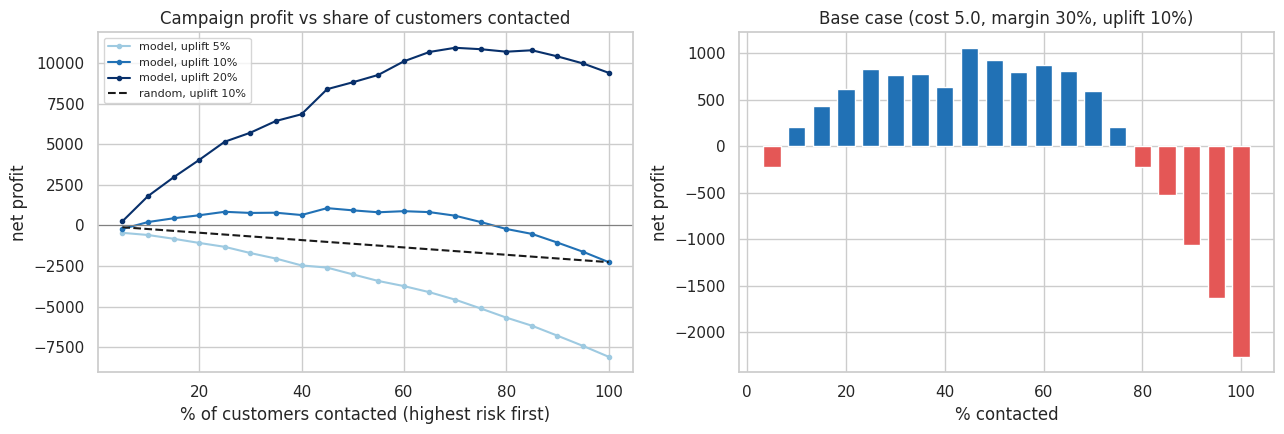

,profit_model,profit_random,gain_vs_random
contacted_%,,,
5,-225.0,-113.0,-112.0
10,204.0,-227.0,430.0
20,621.0,-453.0,1074.0
30,765.0,-680.0,1445.0
50,925.0,-1133.0,2058.0
100,-2265.0,-2265.0,0.0


Base case: profit is maximised by contacting the top 45% -> net profit 1,060 (random targeting at the same reach: -1,019)


In [41]:
COST, MARGIN, UPLIFT = 5.0, 0.30, 0.10          # per contact (currency units) | gross margin | retention uplift
fr_grid = np.round(np.arange(0.05, 1.0001, 0.05), 2)
sim = test[["churn", "avg_order_value"]].reset_index(drop=True)
n_sim = len(sim); value_if_saved = (sim.churn * sim.avg_order_value).to_numpy()


def profit_targeted(score, frac, uplift, cost=COST, margin=MARGIN):
    flag = flag_top(score, frac).astype(bool)
    return uplift * margin * value_if_saved[flag].sum() - cost * flag.sum()


def profit_random(frac, uplift, cost=COST, margin=MARGIN):     # expected value of contacting a random `frac`
    return frac * (uplift * margin * value_if_saved.sum() - cost * n_sim)


fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for u, col in zip([0.05, 0.10, 0.20], ["#9ecae1", "#2171b5", "#08306b"]):
    ax[0].plot(fr_grid * 100, [profit_targeted(s_final, f, u) for f in fr_grid], c=col, marker="o", ms=3, label=f"model, uplift {u:.0%}")
ax[0].plot(fr_grid * 100, [profit_random(f, UPLIFT) for f in fr_grid], "k--", label=f"random, uplift {UPLIFT:.0%}")
ax[0].axhline(0, c="grey", lw=.8)
ax[0].set(title="Campaign profit vs share of customers contacted", xlabel="% of customers contacted (highest risk first)", ylabel="net profit")
ax[0].legend(fontsize=8)

prof = np.array([profit_targeted(s_final, f, UPLIFT) for f in fr_grid])
best_frac = fr_grid[prof.argmax()]
ax[1].bar(fr_grid * 100, prof, width=3.5, color=np.where(prof >= 0, "#2171b5", "#E45756"))
ax[1].set(title=f"Base case (cost {COST}, margin {MARGIN:.0%}, uplift {UPLIFT:.0%})", xlabel="% contacted", ylabel="net profit")
show("roi_simulation")

roi_tbl = pd.DataFrame({"contacted_%": (fr_grid * 100).astype(int),
                        "profit_model": prof,
                        "profit_random": [profit_random(f, UPLIFT) for f in fr_grid]})
roi_tbl["gain_vs_random"] = roi_tbl.profit_model - roi_tbl.profit_random
display(roi_tbl[roi_tbl["contacted_%"].isin([5, 10, 20, 30, 50, 100])].round(0).set_index("contacted_%"))
roi_tbl.round(2).to_csv(OUT_DIR / "roi_simulation.csv", index=False)
print(f"Base case: profit is maximised by contacting the top {best_frac:.0%} -> net profit {prof.max():,.0f} "
      f"(random targeting at the same reach: {profit_random(best_frac, UPLIFT):,.0f})")

**How to read it:** the gap between the model curve and the dashed random line is the value of ranking. If profit keeps rising up to 100% contacted, the offer is so cheap relative to customer value that targeting barely matters; if it peaks at a small share, targeting is what makes the campaign profitable. Either way the conclusion depends on `COST`, `MARGIN` and `UPLIFT`, which is why they are explicit parameters, and a real A/B test is needed to measure the true uplift.

In the base case here, profit peaks at about 45% reach and turns negative at 100%, so ranking matters: contacting everyone loses money, while contacting the highest-risk customers first does not.

**Caution:** the absolute profit is small and depends entirely on the three assumed parameters
(cost, margin, uplift). Only the *relative* comparison is meaningful: under the same assumptions,
model-based targeting earns more than random contact. The real uplift must be measured with an
A/B test before any profit figure is quoted.

## 8. Conclusions & limitations

In [42]:
rule_r, fin = res.loc[RULE], res.loc[FINAL]
beats = pr_ci[FINAL][0] > pr_ci[RULE][1]
stack_gain = res.loc["Stacking", "cv_pr_auc"] - res.drop(index=["Stacking", RULE]).cv_pr_auc.max()
hi_t = tier.loc["High (top 10%)"]
summary = f"""
**Key results** (train {len(train):,} / test {len(test):,} customers; base churn rate {ytr.mean():.1%} / {yte.mean():.1%})

- **ML vs one-line rule:** {FINAL} reaches test PR-AUC **{fin.test_pr_auc:.3f}** {fin.test_pr_auc_ci95} vs **{rule_r.test_pr_auc:.3f}** {rule_r.test_pr_auc_ci95} for the recency rule. {"The intervals do not overlap, so the improvement is meaningful." if beats else "The intervals overlap, so the improvement is not conclusive."} Test ROC-AUC is {fin.test_roc_auc:.3f}.
- **Ensemble:** stacking changes CV PR-AUC by {stack_gain:+.3f} vs the best single model, so {"it adds nothing meaningful and the simpler, interpretable model is preferred." if stack_gain < 0.005 else "it gives a gain worth considering."}
- **Stability:** across {len(bt)} backtest periods, ROC-AUC is {bt.roc_auc.mean():.3f} ± {bt.roc_auc.std():.3f}; PR-AUC mostly tracks the base rate (corr {corr_pr_base:.2f}).
- **Business use:** the top 10% by risk has a churn rate of {hi_t.actual_churn_rate:.0%} ({hi_t.lift_vs_average:.1f}x average) and reaches {100 * np.interp(.10, gains_x, gains_y):.0f}% of all churners; the top {CAPACITY:.0%} reaches {100 * np.interp(CAPACITY, gains_x, gains_y):.0f}%.
- **ROI (illustrative assumptions: cost {COST}, margin {MARGIN:.0%}, uplift {UPLIFT:.0%}):** {f"targeting by risk score beats random contact by about {prof.max() - profit_random(best_frac, UPLIFT):,.0f} currency units at the same reach (top {best_frac:.0%}). Absolute profit is assumption-driven and not a forecast." if prof.max() > 0 else "no reach is profitable under these assumptions; targeting by the model still loses less than random contact."}
- **Accuracy caveat:** at top {CAPACITY:.0%} accuracy is {acc_cap:.3f} vs {majority:.3f} for always predicting the majority class, so ranking metrics and recall are more informative.
- **Features:** {len(FEATURES)} used; dropped for drift: {", ".join(dropped) if dropped else "none"}.
- **Main drivers:** {", ".join(imp.index[:3])}.
"""
display(Markdown(summary)); (OUT_DIR / "results_summary.md").write_text(summary)
joblib.dump({"model": MODELS[FINAL], "features": FEATURES, "final": FINAL}, OUT_DIR / "final_model.joblib")


**Key results** (train 2,640 / test 2,785 customers; base churn rate 50.3% / 38.2%)

- **ML vs one-line rule:** Logistic Regression reaches test PR-AUC **0.635** [0.602, 0.665] vs **0.527** [0.497, 0.557] for the recency rule. The intervals do not overlap, so the improvement is meaningful. Test ROC-AUC is 0.757.
- **Ensemble:** stacking changes CV PR-AUC by -0.002 vs the best single model, so it adds nothing meaningful and the simpler, interpretable model is preferred.
- **Stability:** across 5 backtest periods, ROC-AUC is 0.761 ± 0.021; PR-AUC mostly tracks the base rate (corr 0.97).
- **Business use:** the top 10% by risk has a churn rate of 71% (1.9x average) and reaches 19% of all churners; the top 30% reaches 50%.
- **ROI (illustrative assumptions: cost 5.0, margin 30%, uplift 10%):** targeting by risk score beats random contact by about 2,080 currency units at the same reach (top 45%). Absolute profit is assumption-driven and not a forecast.
- **Accuracy caveat:** at top 30% accuracy is 0.701 vs 0.618 for always predicting the majority class, so ranking metrics and recall are more informative.
- **Features:** 16 used; dropped for drift: tenure_days.
- **Main drivers:** frequency, recency_days, std_gap_days.


['output/final_model.joblib']